In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Input Data and Assumptions ---

# A simple sentence represented by tokens
sentence = ["The", "cat", "sat", "on", "the", "mat"]

# In a real model, these would be learned. We initialize them randomly for this demo.
# d_model: The dimension of the input embeddings (and the model's hidden layers).
# d_k: The dimension of the Key and Query vectors.
d_model = 16
d_k = 4 # Dimension for Q, K vectors. Often d_model / num_heads

print("--- 1. Initializing Inputs and Weights ---")

# Input embeddings for each word in the sentence
# Shape: (sequence_length, d_model)
X = np.random.rand(len(sentence), d_model)
print(f"Input embeddings shape (X): {X.shape}")
print(X)

--- 1. Initializing Inputs and Weights ---
Input embeddings shape (X): (6, 16)
[[0.93629137 0.39855262 0.57498573 0.12782756 0.41929793 0.12897811
  0.37458116 0.3021715  0.27007423 0.74687615 0.59520097 0.58496223
  0.26093173 0.09361302 0.82228697 0.40864165]
 [0.77172514 0.69886791 0.64394143 0.0962953  0.4332305  0.9001449
  0.91722702 0.68575614 0.20621353 0.27547707 0.17140839 0.94290431
  0.15461359 0.93583588 0.98962149 0.67520774]
 [0.64233141 0.27195936 0.95423355 0.74189166 0.59141197 0.91368225
  0.25472172 0.17341678 0.87147875 0.28441177 0.839481   0.83307984
  0.55044224 0.28027962 0.64152859 0.98234328]
 [0.62055164 0.2795313  0.69932722 0.08174996 0.97477772 0.12505329
  0.03324252 0.83820536 0.07609924 0.00183054 0.94575803 0.79278385
  0.39685157 0.94843526 0.01863942 0.06496335]
 [0.92444826 0.58866074 0.19427604 0.53086045 0.04476935 0.34840073
  0.1003492  0.63323404 0.52294621 0.5480203  0.24171047 0.95654952
  0.33903364 0.40747106 0.90292588 0.51924719]
 [0.778

In [3]:

# Weight matrices to project embeddings into Q, K, V spaces
# Shape: (d_model, d_k) for W_q, W_k and (d_model, d_v) for W_v (here d_v=d_k for simplicity)
W_q = np.random.rand(d_model, d_k)
W_k = np.random.rand(d_model, d_k)
W_v = np.random.rand(d_model, d_k)

print(f"Weight matrix shape (W_q, W_k, W_v): {W_q.shape}")
print("-" * 30, "\n")

# --- 2. Project inputs into Query, Key, and Value vectors ---
print("--- 2. Projecting inputs into Q, K, V ---")
Q = X @ W_q
K = X @ W_k
V = X @ W_v

print(f"Query matrix shape (Q): {Q.shape}")
print(f"Key matrix shape (K): {K.shape}")
print(f"Value matrix shape (V): {V.shape}")
print("-" * 30, "\n")


Weight matrix shape (W_q, W_k, W_v): (16, 4)
------------------------------ 

--- 2. Projecting inputs into Q, K, V ---
Query matrix shape (Q): (6, 4)
Key matrix shape (K): (6, 4)
Value matrix shape (V): (6, 4)
------------------------------ 



In [4]:

# --- 3. Calculate Attention Scores ---
# This is the core of the attention mechanism.
# Scores = softmax( (Q * K^T) / sqrt(d_k) )
print("--- 3. Calculating Attention Scores ---")

# Step 3a: Dot product of Queries and Keys
scores = Q @ K.T
print(f"Scores before scaling (Q @ K.T) shape: {scores.shape}")

# Step 3b: Scaling the scores to stabilize gradients
scaled_scores = scores / np.sqrt(d_k)
print(f"Scaled scores shape: {scaled_scores.shape}")

# Step 3c: Applying softmax to get attention weights
# (Directly implementing the softmax calculation here)
exp_scores = np.exp(scaled_scores - np.max(scaled_scores, axis=-1, keepdims=True))
attention_weights = exp_scores / exp_scores.sum(axis=-1, keepdims=True)

print(f"Attention weights (after softmax) shape: {attention_weights.shape}")
print("\nAttention Weights Matrix:\n", np.round(attention_weights, 2))

# --- 4. Compute the final output ---
# The output for each word is a weighted sum of the Value vectors
print("--- 4. Computing Final Output ---")
output = attention_weights @ V
print(f"Final output shape (Attention_Weights @ V): {output.shape}")



--- 3. Calculating Attention Scores ---
Scores before scaling (Q @ K.T) shape: (6, 6)
Scaled scores shape: (6, 6)
Attention weights (after softmax) shape: (6, 6)

Attention Weights Matrix:
 [[0.   0.03 0.97 0.   0.   0.  ]
 [0.   0.01 0.99 0.   0.   0.  ]
 [0.   0.01 0.99 0.   0.   0.  ]
 [0.   0.06 0.94 0.   0.   0.  ]
 [0.   0.02 0.98 0.   0.   0.  ]
 [0.   0.03 0.97 0.   0.   0.  ]]
--- 4. Computing Final Output ---
Final output shape (Attention_Weights @ V): (6, 4)


--- 5. Visualizing the Attention Weights ---


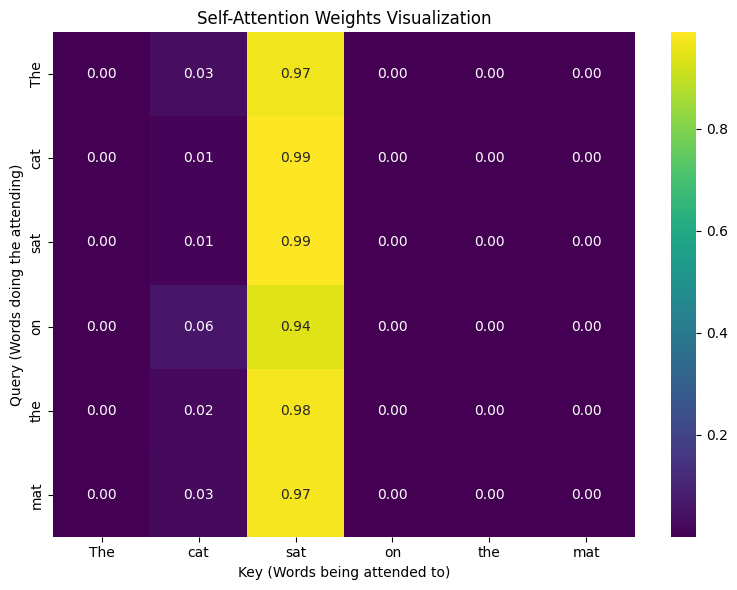

In [5]:

# --- 5. Visualization of Attention Weights ---
print("--- 5. Visualizing the Attention Weights ---")
plt.figure(figsize=(8, 6))
sns.heatmap(attention_weights,
            xticklabels=sentence,
            yticklabels=sentence,
            annot=True,
            cmap="viridis",
            fmt=".2f")
plt.title("Self-Attention Weights Visualization")
plt.xlabel("Key (Words being attended to)")
plt.ylabel("Query (Words doing the attending)")
plt.tight_layout()
plt.show()

